<a href="https://colab.research.google.com/github/Pritipirojia/AI_Engineering_Tutorial_Notes/blob/main/Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Feature Engineering

### Feature Engineering ---> It is the process of creating new and better features for our model from which we can have better insights or we can make better prediction model.

### How to create feature on your own


*   By taking into consideration all the already existing features (columns) which can help us building better prediction model or help us in better analysis.



In [1]:
import pandas as pd
import seaborn as sns

In [2]:
train=pd.read_csv('train.csv')
test=pd.read_csv('test.csv')

In [3]:
train.shape

(891, 12)

In [4]:
test.shape

(418, 11)

In [5]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [7]:
df=pd.concat([train,test])

In [8]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


i. Family size ---> passenger + sibsp + parch

Family size vs survived ---> what are the chances of survival based on the family size

In [10]:
df['Family Size']=df['SibSp']+df['Parch']+1

In [11]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1


<Axes: xlabel='Family Size', ylabel='Survived'>

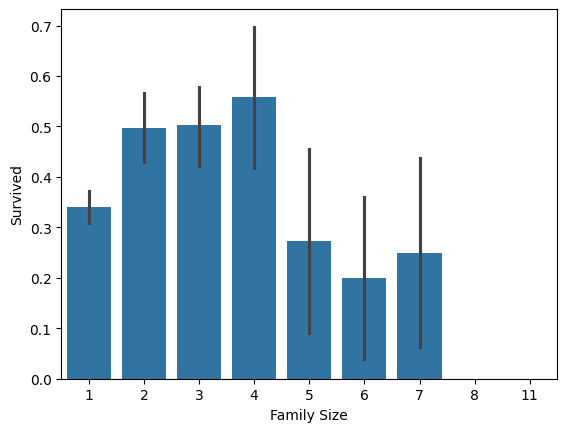

In [12]:
sns.barplot(data=df,x='Family Size',y='Survived')

If family size < 3 ---> family type= small family
If family size >= 3 & family size < 5 ---> family type= medium family
If family size >= 5 ---> family type= large family

(small, medium, large) family vs survived

In [14]:
def fam_type(num):
  if num>=1 and num<=3:
    return 'Small Family'
  elif num>=3 and num<5:
    return 'Medium Family'
  else:
    return 'Large Family'

In [15]:
df['Family Type']=df['Family Size'].apply(fam_type)

In [17]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Family Type
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,Small Family
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,Small Family
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,Small Family
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,Small Family
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,Small Family


In [18]:
df['Family Type'].value_counts()

,count
Family Type,
Small Family,1184
Large Family,82
Medium Family,43


In [20]:
pd.crosstab(df['Family Type'],df['Survived'],normalize=True)*100

Survived,0.0,1.0
Family Type,,
Large Family,5.836139,1.122334
Medium Family,0.897868,2.356902
Small Family,54.882155,34.904602


<Axes: xlabel='Survived', ylabel='Family Type'>

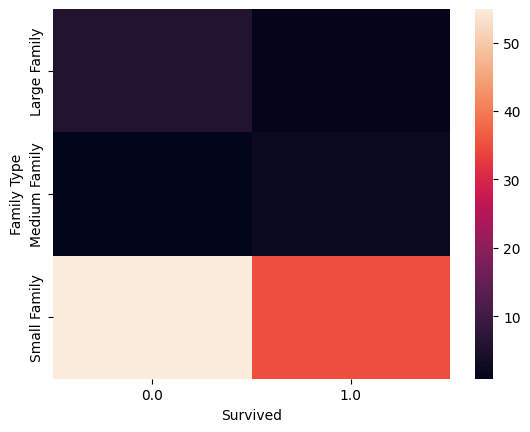

In [21]:
sns.heatmap(pd.crosstab(df['Family Type'],df['Survived'],normalize=True)*100)

In [22]:
df[df['SibSp']==5]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Family Type
59,60,0.0,3,"Goodwin, Master. William Frederick",male,11.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
71,72,0.0,3,"Goodwin, Miss. Lillian Amy",female,16.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
386,387,0.0,3,"Goodwin, Master. Sidney Leonard",male,1.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
480,481,0.0,3,"Goodwin, Master. Harold Victor",male,9.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
683,684,0.0,3,"Goodwin, Mr. Charles Edward",male,14.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
140,1032,NaN,3,"Goodwin, Miss. Jessie Allis",female,10.0,5,2,CA 2144,46.9,NaN,S,8,Large Family


In [23]:
df[df['Ticket']=='CA 2144']

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Family Type
59,60,0.0,3,"Goodwin, Master. William Frederick",male,11.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
71,72,0.0,3,"Goodwin, Miss. Lillian Amy",female,16.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
386,387,0.0,3,"Goodwin, Master. Sidney Leonard",male,1.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
480,481,0.0,3,"Goodwin, Master. Harold Victor",male,9.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
678,679,0.0,3,"Goodwin, Mrs. Frederick (Augusta Tyler)",female,43.0,1,6,CA 2144,46.9,NaN,S,8,Large Family
683,684,0.0,3,"Goodwin, Mr. Charles Edward",male,14.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
139,1031,NaN,3,"Goodwin, Mr. Charles Frederick",male,40.0,1,6,CA 2144,46.9,NaN,S,8,Large Family
140,1032,NaN,3,"Goodwin, Miss. Jessie Allis",female,10.0,5,2,CA 2144,46.9,NaN,S,8,Large Family


individual fare ---> Fare/family size
passenger ---> individual fare ---> what are the chances of survival

In [24]:
df['Individual Fare']=df['Fare']/df['Family Size']

In [25]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Family Type,Individual Fare
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,Small Family,3.62500
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,Small Family,35.64165
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,Small Family,7.92500
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,Small Family,26.55000
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,Small Family,8.05000


In [29]:
df[df['Ticket']=='CA 2144'][['Name','Family Size','Fare','Individual Fare']]

,Name,Family Size,Fare,Individual Fare
59,"Goodwin, Master. William Frederick",8,46.9,5.8625
71,"Goodwin, Miss. Lillian Amy",8,46.9,5.8625
386,"Goodwin, Master. Sidney Leonard",8,46.9,5.8625
480,"Goodwin, Master. Harold Victor",8,46.9,5.8625
678,"Goodwin, Mrs. Frederick (Augusta Tyler)",8,46.9,5.8625
683,"Goodwin, Mr. Charles Edward",8,46.9,5.8625
139,"Goodwin, Mr. Charles Frederick",8,46.9,5.8625
140,"Goodwin, Miss. Jessie Allis",8,46.9,5.8625


Abbreviation or prefix of passenger name

In [30]:
df['Name'].str.split(',')

,Name
0,"[Braund, Mr. Owen Harris]"
1,"[Cumings, Mrs. John Bradley (Florence Briggs ..."
2,"[Heikkinen, Miss. Laina]"
3,"[Futrelle, Mrs. Jacques Heath (Lily May Peel)]"
4,"[Allen, Mr. William Henry]"
...,...
413,"[Spector, Mr. Woolf]"
414,"[Oliva y Ocana, Dona. Fermina]"
415,"[Saether, Mr. Simon Sivertsen]"
416,"[Ware, Mr. Frederick]"


In [31]:
df['Name'].str.split(',').str[1]

,Name
0,Mr. Owen Harris
1,Mrs. John Bradley (Florence Briggs Thayer)
2,Miss. Laina
3,Mrs. Jacques Heath (Lily May Peel)
4,Mr. William Henry
...,...
413,Mr. Woolf
414,Dona. Fermina
415,Mr. Simon Sivertsen
416,Mr. Frederick


In [34]:
df['Name Prefix']=df['Name'].str.split(',').str[1].str.split('.').str[0].str.strip()

In [35]:
df['Name Prefix'].value_counts()

,count
Name Prefix,
Mr,757
Miss,260
Mrs,197
Master,61
Rev,8
Dr,8
Col,4
Major,2
Mlle,2
